<a href="https://colab.research.google.com/github/Sangbartika-c/Personal-Notes-and-Reminder-App/blob/main/DS_HEART_DISEASE_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. Import Libraries
# ============================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

In [2]:
# 2. Load Dataset
# ============================================

df = pd.read_csv("/content/heart_attack_prediction_dataset.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

Dataset Shape: (8763, 26)

First 5 rows:
  Patient ID  Age     Sex  Cholesterol Blood Pressure  Heart Rate  Diabetes  \
0    BMW7812   67    Male          208         158/88          72         0   
1    CZE1114   21    Male          389         165/93          98         1   
2    BNI9906   21  Female          324         174/99          72         1   
3    JLN3497   84    Male          383        163/100          73         1   
4    GFO8847   66    Male          318          91/88          93         1   

   Family History  Smoking  Obesity  ...  Sedentary Hours Per Day  Income  \
0               0        1        0  ...                 6.615001  261404   
1               1        1        1  ...                 4.963459  285768   
2               0        0        0  ...                 9.463426  235282   
3               1        1        0  ...                 7.648981  125640   
4               1        1        1  ...                 1.514821  160555   

         BMI  Triglyc

In [3]:
# 3. Check Missing Values
# ============================================

print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Patient ID                         0
Age                                0
Sex                                0
Cholesterol                        0
Blood Pressure                     0
Heart Rate                         0
Diabetes                           0
Family History                     0
Smoking                            0
Obesity                            0
Alcohol Consumption                0
Exercise Hours Per Week            0
Diet                               0
Previous Heart Problems            0
Medication Use                     0
Stress Level                       0
Sedentary Hours Per Day            0
Income                             0
BMI                                0
Triglycerides                      0
Physical Activity Days Per Week    0
Sleep Hours Per Day                0
Country                            0
Continent                          0
Hemisphere                         0
Heart Attack Risk                  0
dtype: int64


In [4]:

# 4. Remove Patient ID
# ============================================

# Patient ID is an identifier and is not useful
# for predicting heart attack risk.

if "Patient ID" in df.columns:
    df = df.drop("Patient ID", axis=1)

print("Patient ID removed successfully!")
print("Dataset Shape:", df.shape)


Patient ID removed successfully!
Dataset Shape: (8763, 25)


In [5]:
print(df.columns.tolist())

['Age', 'Sex', 'Cholesterol', 'Blood Pressure', 'Heart Rate', 'Diabetes', 'Family History', 'Smoking', 'Obesity', 'Alcohol Consumption', 'Exercise Hours Per Week', 'Diet', 'Previous Heart Problems', 'Medication Use', 'Stress Level', 'Sedentary Hours Per Day', 'Income', 'BMI', 'Triglycerides', 'Physical Activity Days Per Week', 'Sleep Hours Per Day', 'Country', 'Continent', 'Hemisphere', 'Heart Attack Risk']


In [6]:
# 5. Process Blood Pressure and Remove Duplicates
# ============================================

# Remove duplicate records
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

# Check whether Blood Pressure exists
if "Blood Pressure" in df.columns:

    # Split Blood Pressure into two columns
    df[["Systolic BP", "Diastolic BP"]] = (
        df["Blood Pressure"].astype(str).str.split("/", expand=True)
    )

    # Convert into numerical values
    df["Systolic BP"] = pd.to_numeric(
        df["Systolic BP"], errors="coerce"
    )

    df["Diastolic BP"] = pd.to_numeric(
        df["Diastolic BP"], errors="coerce"
    )

    # Remove original column
    df = df.drop("Blood Pressure", axis=1)

    print("Blood Pressure processed successfully!")

elif "Systolic BP" in df.columns and "Diastolic BP" in df.columns:

    print("Blood Pressure is already processed!")

else:
    print("Blood Pressure column not found. Check dataset columns.")

print("\nFinal Dataset Shape:", df.shape)
print("\nAvailable Columns:")
print(df.columns.tolist())

Dataset Shape After Removing Duplicates: (8763, 25)
Blood Pressure processed successfully!

Final Dataset Shape: (8763, 26)

Available Columns:
['Age', 'Sex', 'Cholesterol', 'Heart Rate', 'Diabetes', 'Family History', 'Smoking', 'Obesity', 'Alcohol Consumption', 'Exercise Hours Per Week', 'Diet', 'Previous Heart Problems', 'Medication Use', 'Stress Level', 'Sedentary Hours Per Day', 'Income', 'BMI', 'Triglycerides', 'Physical Activity Days Per Week', 'Sleep Hours Per Day', 'Country', 'Continent', 'Hemisphere', 'Heart Attack Risk', 'Systolic BP', 'Diastolic BP']


In [8]:
# Separate independent and dependent variables

X = df.drop('Heart Attack Risk', axis=1)
y = df['Heart Attack Risk']

In [9]:
# 7. Train-Test Split
# ============================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (7010, 25)
Testing Data: (1753, 25)


In [11]:
# Identify numerical columns

numerical_columns = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Remove Patient ID if present
numerical_columns = [
    col for col in numerical_columns
    if col != 'Patient ID'
]

print("Numerical Columns:", numerical_columns)

Numerical Columns: ['Age', 'Cholesterol', 'Heart Rate', 'Diabetes', 'Family History', 'Smoking', 'Obesity', 'Alcohol Consumption', 'Exercise Hours Per Week', 'Previous Heart Problems', 'Medication Use', 'Stress Level', 'Sedentary Hours Per Day', 'Income', 'BMI', 'Triglycerides', 'Physical Activity Days Per Week', 'Sleep Hours Per Day', 'Systolic BP', 'Diastolic BP']


In [12]:
# 8. Handle Outliers Using IQR
# ============================================

Q1 = X_train[numerical_columns].quantile(0.25)
Q3 = X_train[numerical_columns].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Cap outliers in training data
X_train[numerical_columns] = X_train[
    numerical_columns
].clip(lower=lower_limit, upper=upper_limit, axis=1)

# Apply the same limits to testing data
X_test[numerical_columns] = X_test[
    numerical_columns
].clip(lower=lower_limit, upper=upper_limit, axis=1)

print("Outlier handling completed!")

Outlier handling completed!


In [14]:
# Identify categorical columns

categorical_columns = X_train.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Categorical Columns:", categorical_columns)

Categorical Columns: ['Sex', 'Diet', 'Country', 'Continent', 'Hemisphere']


In [15]:
# 9. Create Preprocessing Pipeline
# ============================================

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

# Fit on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Processed Training Data:", X_train_processed.shape)
print("Processed Testing Data:", X_test_processed.shape)

print("Preprocessing completed successfully!")

Processed Training Data: (7010, 53)
Processed Testing Data: (1753, 53)
Preprocessing completed successfully!


In [16]:
# 10. Statistical Analysis
# ============================================

print("Dataset Statistical Summary:")
print(df.describe())

print("\nHeart Attack Risk Distribution:")
print(df["Heart Attack Risk"].value_counts())

print("\nPercentage Distribution:")
print(df["Heart Attack Risk"].value_counts(normalize=True) * 100)

Dataset Statistical Summary:
               Age  Cholesterol   Heart Rate     Diabetes  Family History  \
count  8763.000000  8763.000000  8763.000000  8763.000000     8763.000000   
mean     53.707977   259.877211    75.021682     0.652288        0.492982   
std      21.249509    80.863276    20.550948     0.476271        0.499979   
min      18.000000   120.000000    40.000000     0.000000        0.000000   
25%      35.000000   192.000000    57.000000     0.000000        0.000000   
50%      54.000000   259.000000    75.000000     1.000000        0.000000   
75%      72.000000   330.000000    93.000000     1.000000        1.000000   
max      90.000000   400.000000   110.000000     1.000000        1.000000   

           Smoking      Obesity  Alcohol Consumption  Exercise Hours Per Week  \
count  8763.000000  8763.000000          8763.000000              8763.000000   
mean      0.896839     0.501426             0.598083                10.014284   
std       0.304186     0.500026   

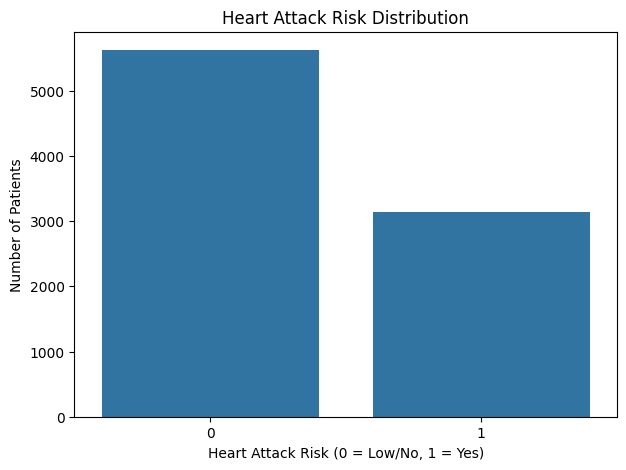

In [17]:
# 11. Heart Attack Risk Distribution
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Heart Attack Risk"
)

plt.title("Heart Attack Risk Distribution")
plt.xlabel("Heart Attack Risk (0 = Low/No, 1 = Yes)")
plt.ylabel("Number of Patients")

plt.show()

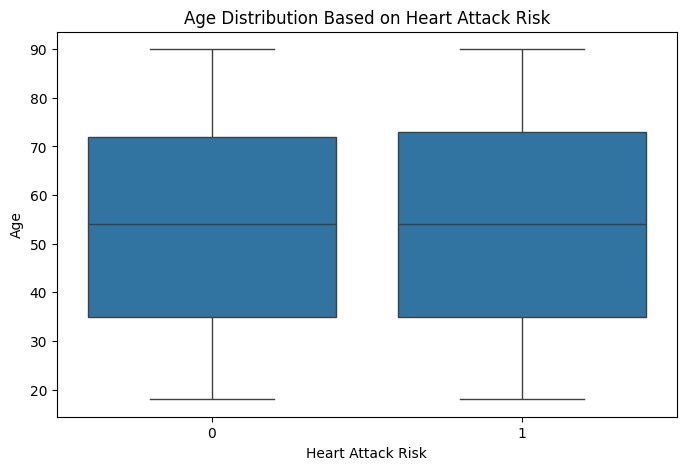

In [18]:
# 12. Age vs Heart Attack Risk
# ============================================

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Heart Attack Risk",
    y="Age"
)

plt.title("Age Distribution Based on Heart Attack Risk")
plt.xlabel("Heart Attack Risk")
plt.ylabel("Age")

plt.show()

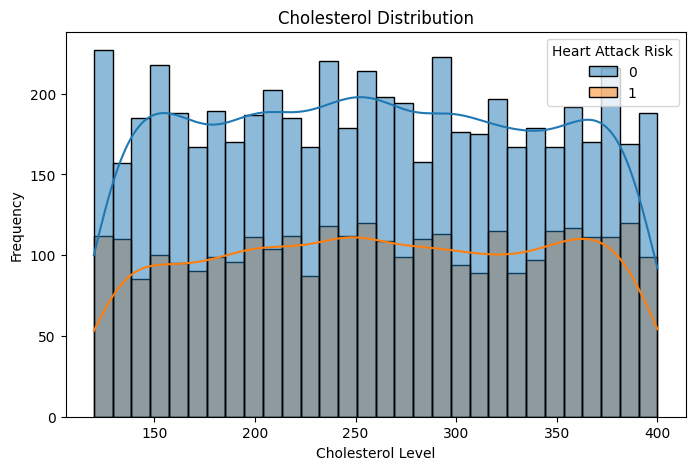

In [19]:
# 13. Cholesterol Analysis
# ============================================

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Cholesterol",
    hue="Heart Attack Risk",
    kde=True,
    bins=30
)

plt.title("Cholesterol Distribution")
plt.xlabel("Cholesterol Level")
plt.ylabel("Frequency")

plt.show()

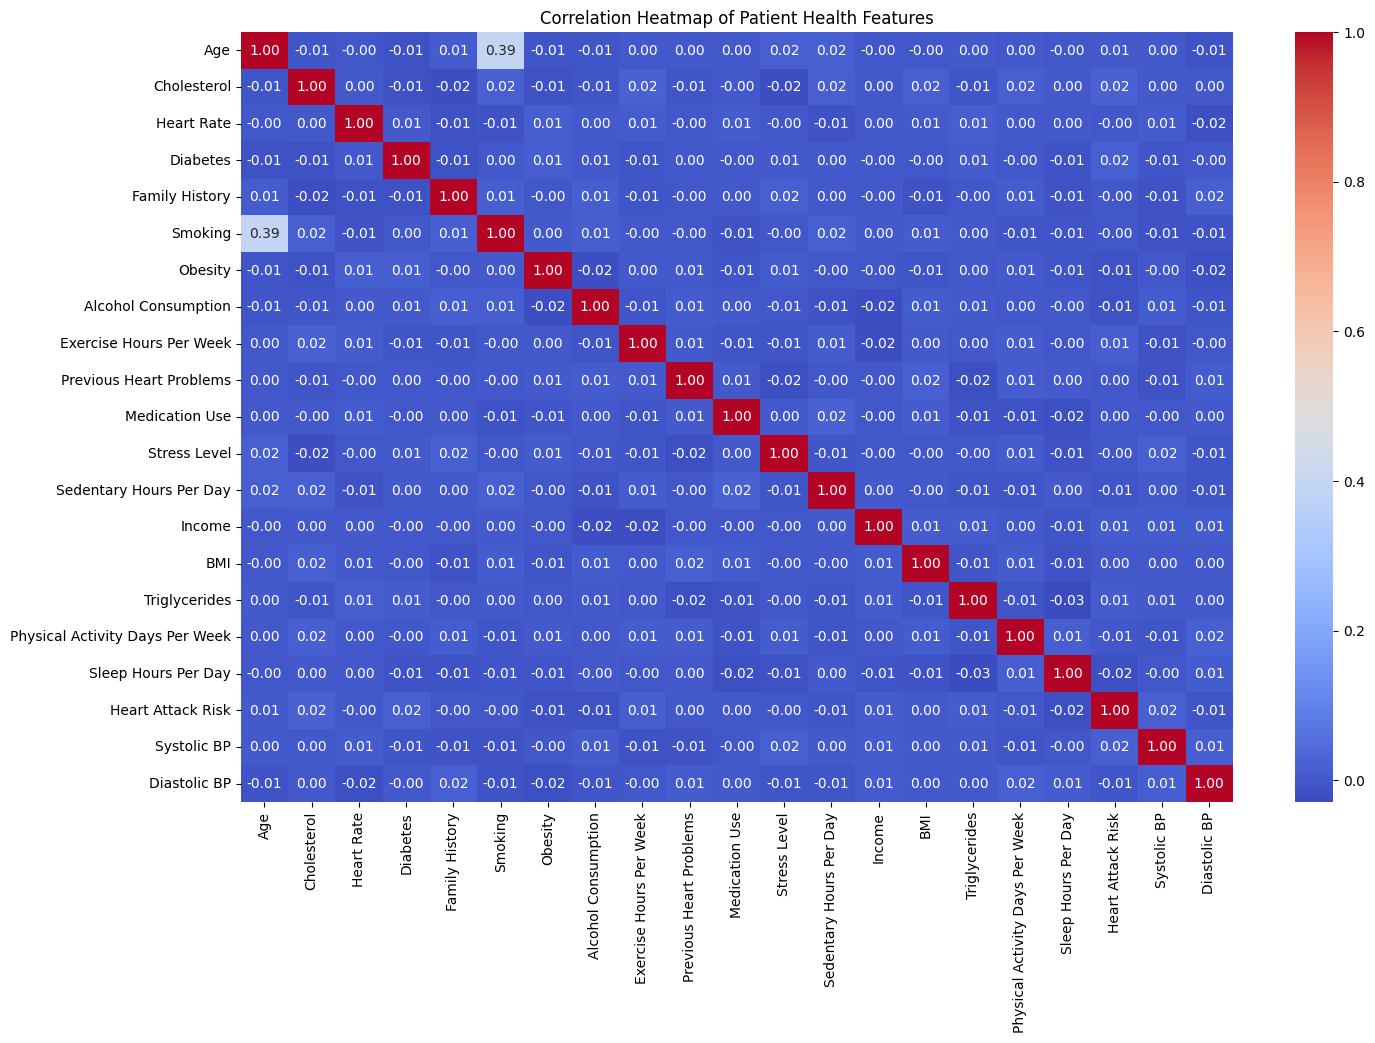

In [20]:
# 14. Correlation Heatmap
# ============================================

plt.figure(figsize=(16, 10))

correlation = df.select_dtypes(
    include=["number"]
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Patient Health Features")

plt.show()

In [21]:
# 15. Linear Regression
# ============================================

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

linear_model = LinearRegression()

# Train model
linear_model.fit(X_train_processed, y_train)

# Prediction
linear_predictions = linear_model.predict(X_test_processed)

# Convert predictions into risk scores
risk_scores = np.clip(
    linear_predictions * 100,
    0,
    100
)

# Evaluation
print("Linear Regression Results")

print("MAE:",
      mean_absolute_error(y_test, linear_predictions))

print("MSE:",
      mean_squared_error(y_test, linear_predictions))

print("RMSE:",
      np.sqrt(mean_squared_error(y_test, linear_predictions)))

print("R2 Score:",
      r2_score(y_test, linear_predictions))

print("\nSample Risk Scores:")
print(risk_scores[:10])

Linear Regression Results
MAE: 0.45949667602822664
MSE: 0.23092949692398845
RMSE: 0.48055124276604305
R2 Score: -0.004456365764881287

Sample Risk Scores:
[32.96362808 35.55323223 39.2417828  29.65519948 35.84547785 40.61380577
 34.0130139  32.52830279 39.11054917 37.40822105]


In [22]:
# 16. Logistic Regression
# ============================================

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train model
logistic_model.fit(X_train_processed, y_train)

# Predict
logistic_predictions = logistic_model.predict(
    X_test_processed
)

# Evaluation
print("Logistic Regression Results")

print("Accuracy:",
      accuracy_score(y_test, logistic_predictions))

print("\nClassification Report:")

print(classification_report(
    y_test,
    logistic_predictions,
    zero_division=0
))

print("\nConfusion Matrix:")

print(confusion_matrix(
    y_test,
    logistic_predictions
))

Logistic Regression Results
Accuracy: 0.6417569880205363

Classification Report:
              precision    recall  f1-score   support

           0       0.64      1.00      0.78      1125
           1       0.00      0.00      0.00       628

    accuracy                           0.64      1753
   macro avg       0.32      0.50      0.39      1753
weighted avg       0.41      0.64      0.50      1753


Confusion Matrix:
[[1125    0]
 [ 628    0]]


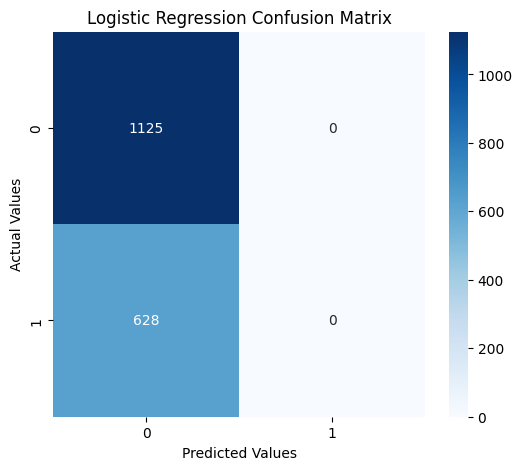

In [23]:
# 17. Confusion Matrix Visualization
# ============================================

plt.figure(figsize=(6, 5))

sns.heatmap(
    confusion_matrix(y_test, logistic_predictions),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [24]:
# 18. K-Nearest Neighbors
# ============================================

from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

# Train model
knn_model.fit(X_train_processed, y_train)

# Prediction
knn_predictions = knn_model.predict(
    X_test_processed
)

print("KNN Results")

print("Accuracy:",
      accuracy_score(y_test, knn_predictions))

print("\nClassification Report:")

print(classification_report(
    y_test,
    knn_predictions,
    zero_division=0
))

KNN Results
Accuracy: 0.5613234455219623

Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.76      0.69      1125
           1       0.33      0.21      0.26       628

    accuracy                           0.56      1753
   macro avg       0.48      0.48      0.47      1753
weighted avg       0.52      0.56      0.53      1753



In [25]:
# 19. Find Similar Patients
# ============================================

from sklearn.neighbors import NearestNeighbors

nearest_model = NearestNeighbors(
    n_neighbors=5,
    metric="euclidean"
)

nearest_model.fit(X_train_processed)

# Select one test patient
patient_index = 0

patient_data = X_test_processed[patient_index].reshape(1, -1)

# Find nearest patients
distances, indices = nearest_model.kneighbors(patient_data)

print("Selected Patient Index:", patient_index)

print("\nFive Similar Patients:")

similar_patients = X_train.iloc[indices[0]].copy()

similar_patients["Actual Heart Attack Risk"] = (
    y_train.iloc[indices[0]].values
)

print(similar_patients)

print("\nDistances:")
print(distances[0])

Selected Patient Index: 0

Five Similar Patients:
      Age     Sex  Cholesterol  Heart Rate  Diabetes  Family History  Smoking  \
5354   20  Female          294          73         0               0        1   
1915   34    Male          205          93         1               0        1   
5430   67    Male          216         103         0               0        1   
3748   27    Male          275          81         0               0        1   
1403   42    Male          326          96         0               0        1   

      Obesity  Alcohol Consumption  Exercise Hours Per Week  ...        BMI  \
5354        1                    1                 6.249872  ...  39.714240   
1915        1                    1                 8.176610  ...  34.369766   
5430        0                    1                10.947692  ...  32.326084   
3748        1                    1                16.275958  ...  30.720929   
1403        1                    1                 1.957119  ...  39

In [26]:
# 20. K-Means Clustering
# ============================================

from sklearn.cluster import KMeans

kmeans_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit clustering model on training data
train_clusters = kmeans_model.fit_predict(
    X_train_processed
)

# Predict clusters for testing data
test_clusters = kmeans_model.predict(
    X_test_processed
)

# Calculate average target risk in each cluster
cluster_risk = {}

for cluster in range(3):

    cluster_indices = np.where(
        train_clusters == cluster
    )[0]

    average_risk = y_train.iloc[
        cluster_indices
    ].mean()

    cluster_risk[cluster] = average_risk

# Rank clusters by average risk
sorted_clusters = sorted(
    cluster_risk,
    key=cluster_risk.get
)

risk_labels = ["Low", "Medium", "High"]

cluster_mapping = {
    cluster: label
    for cluster, label in zip(
        sorted_clusters,
        risk_labels
    )
}

# Assign risk categories
test_risk_categories = [
    cluster_mapping[cluster]
    for cluster in test_clusters
]

print("Cluster Risk Analysis:")

for cluster, risk in cluster_risk.items():

    print(
        f"Cluster {cluster}: "
        f"Average Risk = {risk:.3f}, "
        f"Category = {cluster_mapping[cluster]}"
    )

Cluster Risk Analysis:
Cluster 0: Average Risk = 0.351, Category = Low
Cluster 1: Average Risk = 0.366, Category = High
Cluster 2: Average Risk = 0.359, Category = Medium


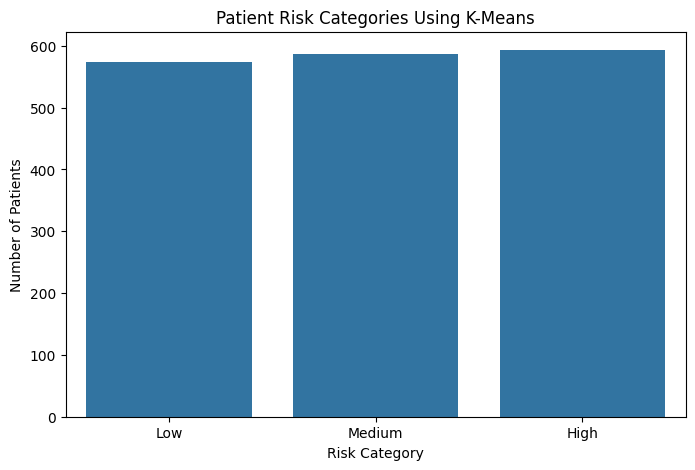

In [27]:
# 21. K-Means Cluster Visualization
# ============================================

cluster_df = pd.DataFrame({
    "Cluster": test_clusters,
    "Risk Category": test_risk_categories,
    "Actual Risk": y_test.values
})

plt.figure(figsize=(8, 5))

sns.countplot(
    data=cluster_df,
    x="Risk Category",
    order=["Low", "Medium", "High"]
)

plt.title("Patient Risk Categories Using K-Means")
plt.xlabel("Risk Category")
plt.ylabel("Number of Patients")

plt.show()

In [28]:
# 22. Logistic Regression Optimization
# ============================================

from sklearn.model_selection import GridSearchCV

parameter_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["lbfgs"],
    "class_weight": [None, "balanced"]
}

grid_search = GridSearchCV(
    LogisticRegression(max_iter=2000, random_state=42),
    parameter_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Train optimized model
grid_search.fit(X_train_processed, y_train)

# Best model
best_model = grid_search.best_estimator_

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(grid_search.best_score_)

Best Parameters:
{'C': 0.01, 'class_weight': None, 'solver': 'lbfgs'}

Best Cross-Validation Accuracy:
0.6417974322396576


In [29]:
# 23. Cross-Validation
# ============================================

from sklearn.model_selection import cross_val_score

models = {
    "Linear Regression": LinearRegression(),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    )
}

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train_processed,
        y_train,
        cv=5,
        scoring="accuracy" if name != "Linear Regression" else "r2"
    )

    print("\n", name)

    print("Cross Validation Scores:", scores)

    print("Average Score:", scores.mean())


 Linear Regression
Cross Validation Scores: [-0.00400471 -0.00870919 -0.01026587 -0.00622857 -0.01073225]
Average Score: -0.007988118251221143

 Logistic Regression
Cross Validation Scores: [0.64194009 0.64194009 0.64194009 0.64194009 0.64122682]
Average Score: 0.6417974322396576

 KNN
Cross Validation Scores: [0.55349501 0.56776034 0.55991441 0.56276748 0.56704708]
Average Score: 0.5621968616262483


                           Model  Accuracy
0            Logistic Regression  0.641757
1                            KNN  0.561323
2  Optimized Logistic Regression  0.641757


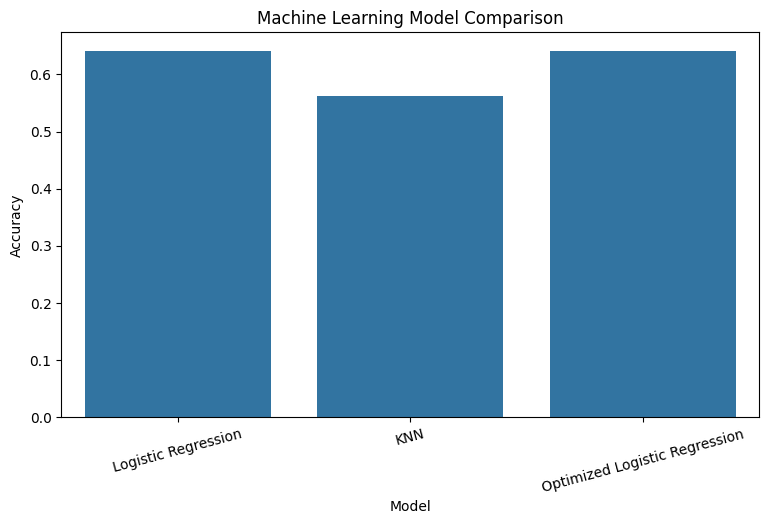

In [30]:
# 24. Model Comparison
# ============================================

from sklearn.metrics import accuracy_score

model_results = {
    "Logistic Regression": accuracy_score(
        y_test, logistic_predictions
    ),

    "KNN": accuracy_score(
        y_test, knn_predictions
    ),

    "Optimized Logistic Regression": accuracy_score(
        y_test,
        best_model.predict(X_test_processed)
    )
}

comparison_df = pd.DataFrame(
    list(model_results.items()),
    columns=["Model", "Accuracy"]
)

print(comparison_df)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Accuracy"
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.xticks(rotation=15)

plt.show()

In [31]:
# 25. Final Patient Risk Analysis
# ============================================

# Use optimized Logistic Regression
final_predictions = best_model.predict(
    X_test_processed
)

# Generate risk scores using Linear Regression
final_risk_scores = np.clip(
    linear_model.predict(X_test_processed) * 100,
    0,
    100
)

# Generate risk categories using K-Means
final_risk_categories = test_risk_categories

# Create final results DataFrame
results = pd.DataFrame({

    "Actual Risk": y_test.values,

    "Predicted Risk": final_predictions,

    "Risk Score (%)": np.round(
        final_risk_scores, 2
    ),

    "Risk Category": final_risk_categories

})

# Display first 10 patients
print("Final Patient Risk Analysis:")

print(results.head(10))

Final Patient Risk Analysis:
   Actual Risk  Predicted Risk  Risk Score (%) Risk Category
0            0               0           32.96           Low
1            0               0           35.55        Medium
2            0               0           39.24        Medium
3            1               0           29.66           Low
4            0               0           35.85        Medium
5            1               0           40.61          High
6            1               0           34.01           Low
7            0               0           32.53           Low
8            1               0           39.11        Medium
9            0               0           37.41        Medium


In [32]:
# 26. Individual Patient Risk Analysis
# ============================================

patient_index = 0

patient = X_test.iloc[patient_index]

prediction = final_predictions[patient_index]

risk_score = final_risk_scores[patient_index]

risk_category = final_risk_categories[patient_index]

print("===================================")
print("       PATIENT RISK REPORT")
print("===================================")

print("\nPatient Medical Information:")

print(patient)

print("\nHeart Attack Risk Prediction:")

if prediction == 1:
    print("Yes - Positive Prediction")
else:
    print("No - Negative Prediction")

print("\nPredicted Risk Score:", risk_score, "%")

print("Patient Risk Category:", risk_category)

print("===================================")

       PATIENT RISK REPORT

Patient Medical Information:
Age                                                 33
Sex                                               Male
Cholesterol                                        268
Heart Rate                                          90
Diabetes                                             0
Family History                                       0
Smoking                                              1
Obesity                                              1
Alcohol Consumption                                  1
Exercise Hours Per Week                      11.617532
Diet                                         Unhealthy
Previous Heart Problems                              0
Medication Use                                       1
Stress Level                                         1
Sedentary Hours Per Day                       1.792088
Income                                           70688
BMI                                          38.326296
Triglyce

Patient Risk Category Summary:
Risk Category
High      593
Medium    586
Low       574
Name: count, dtype: int64


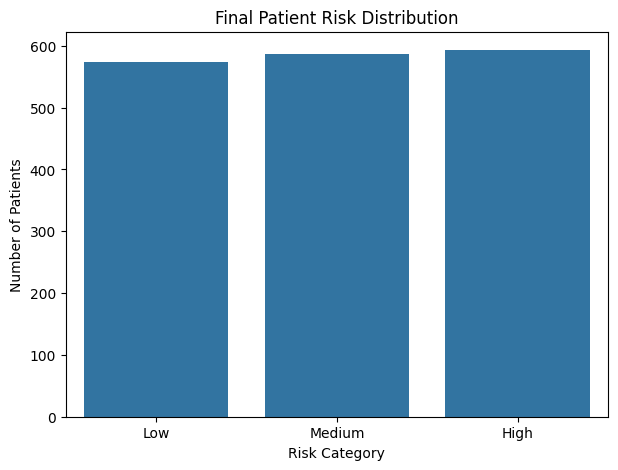

In [33]:
# 27. Final Risk Category Distribution
# ============================================

print("Patient Risk Category Summary:")

print(
    results["Risk Category"].value_counts()
)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=results,
    x="Risk Category",
    order=["Low", "Medium", "High"]
)

plt.title("Final Patient Risk Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Patients")

plt.show()

In [34]:
# 28. Export Patient Risk Analysis
# ============================================

results.to_csv(
    "heart_disease_prediction_results.csv",
    index=False
)

print("Patient risk analysis exported successfully!")

Patient risk analysis exported successfully!
